# Detecção de Fraude em Cartão de Crédito

Base real de transações de cartões europeus (setembro/2013, 2 dias): **284.807 transações, 492 fraudes (0,17%)**.
As colunas `V1`–`V28` vêm de um PCA (anonimização), `Time` são os segundos desde a primeira transação e `Amount` é o valor.

**Por que a acurácia engana aqui:** um modelo que responde "não é fraude" para tudo acerta 99,83% e não pega nenhuma fraude.
Então as métricas que importam são as da **classe fraude**:

| Métrica | Pergunta que responde |
|---|---|
| **Recall** (métrica principal) | De todas as fraudes reais, quantas o modelo pegou? |
| **Precisão** | Dos alertas que o modelo deu, quantos eram fraude mesmo? |
| **F1** | Equilíbrio entre os dois |
| **PR-AUC** (average precision) | Qualidade do ranking de risco, independente do limiar |

**Roteiro:** 1. Explorar → 2. Preparar → 3. Treinar e comparar → 4. Ajustar o limiar → 5. Evoluções (reamostragem, GridSearch, pipeline com limiar, variáveis de tempo) → 6. Explicar com SHAP → 7. Conclusões

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, TunedThresholdClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, fbeta_score, accuracy_score,
                             roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             make_scorer)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
import shap

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
os.makedirs("images", exist_ok=True)

CORES = {"Regressão Logística": "#4C72B0", "Random Forest": "#55A868", "XGBoost": "#C44E52"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Explorar
O dataset é carregado direto pelo link (espelho público do TensorFlow para a base do Kaggle). Nada de CSV no repositório.

In [2]:
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
# Se quiser usar uma cópia local (ex.: rede sem acesso ao link), defina a variável de ambiente CREDITCARD_CSV.
df = pd.read_csv(os.getenv("CREDITCARD_CSV", DATA_URL))
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
print("Valores nulos:", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
df[["Time", "Amount", "Class"]].describe().T

Valores nulos: 0


Linhas duplicadas: 1081


,count,mean,std,min,25%,50%,75%,max
Time,"284,807.0000","94,813.8596","47,488.1460",0.0000,"54,201.5000","84,692.0000","139,320.5000","172,792.0000"
Amount,"284,807.0000",88.3496,250.1201,0.0000,5.6000,22.0000,77.1650,"25,691.1600"
Class,"284,807.0000",0.0017,0.0415,0.0000,0.0000,0.0000,0.0000,1.0000


,Transações,%
Class,,
Normal,284315,99.8273
Fraude,492,0.1727


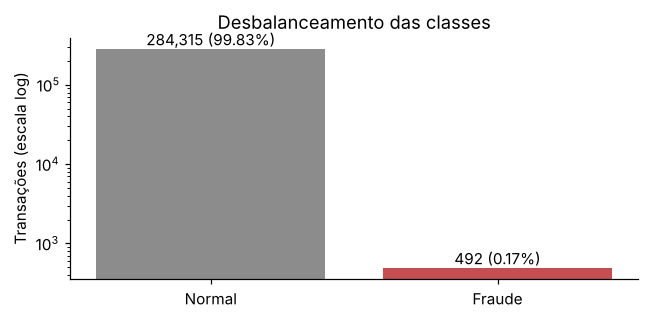

In [4]:
contagem = df["Class"].value_counts().rename({0: "Normal", 1: "Fraude"})
proporcao = df["Class"].value_counts(normalize=True).rename({0: "Normal", 1: "Fraude"}) * 100
display(pd.DataFrame({"Transações": contagem, "%": proporcao}))

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(contagem.index, contagem.values, color=["#8C8C8C", "#C44E52"])
for i, v in enumerate(contagem.values):
    ax.text(i, v, f"{v:,} ({proporcao.values[i]:.2f}%)", ha="center", va="bottom")
ax.set_yscale("log"); ax.set_ylabel("Transações (escala log)"); ax.set_title("Desbalanceamento das classes")
plt.tight_layout(); plt.savefig("images/01_desbalanceamento.png", bbox_inches="tight"); plt.show()

### A armadilha da acurácia
Um classificador que sempre responde a classe majoritária:

In [5]:
dummy = DummyClassifier(strategy="most_frequent").fit(df.drop(columns="Class"), df["Class"])
pred_dummy = dummy.predict(df.drop(columns="Class"))
print(f"Acurácia: {accuracy_score(df['Class'], pred_dummy):.4%}")
print(f"Recall da fraude: {recall_score(df['Class'], pred_dummy):.0%}  -> não pega NENHUMA fraude")

Acurácia: 99.8273%
Recall da fraude: 0%  -> não pega NENHUMA fraude


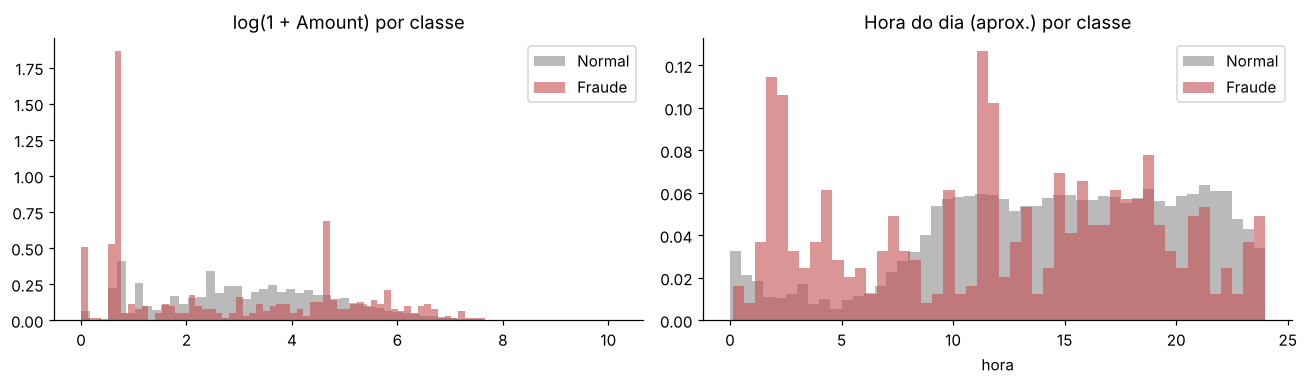

          mean     50%         max
Class                             
0      88.2910 22.0000 25,691.1600
1     122.2113  9.2500  2,125.8700


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for cls, cor, nome in [(0, "#8C8C8C", "Normal"), (1, "#C44E52", "Fraude")]:
    sub = df[df["Class"] == cls]
    axes[0].hist(np.log1p(sub["Amount"]), bins=60, alpha=.6, density=True, color=cor, label=nome)
    axes[1].hist((sub["Time"] / 3600) % 24, bins=48, alpha=.6, density=True, color=cor, label=nome)
axes[0].set_title("log(1 + Amount) por classe"); axes[0].legend()
axes[1].set_title("Hora do dia (aprox.) por classe"); axes[1].set_xlabel("hora"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/02_valor_e_hora.png", bbox_inches="tight"); plt.show()

print(df.groupby("Class")["Amount"].describe()[["mean", "50%", "max"]])

**Leitura:** o valor é muito assimétrico (cauda longa), então o log ajuda. As fraudes se espalham mais pela madrugada, quando o volume de transações normais cai. Isso sugere usar a hora do dia como variável.

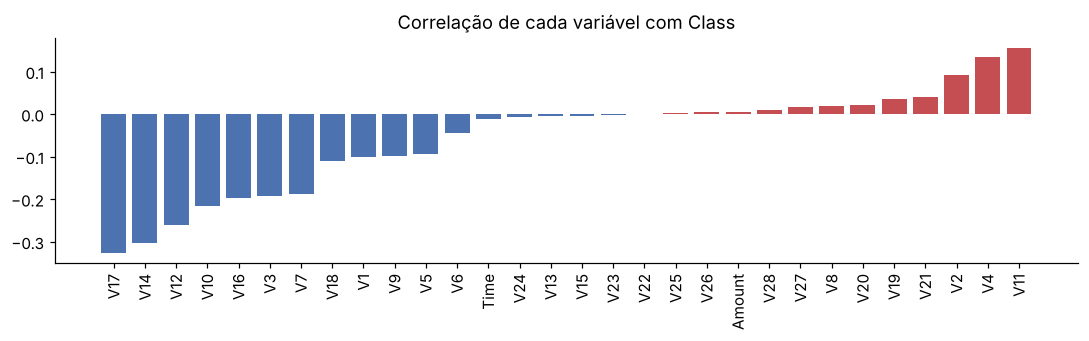

In [7]:
corr = df.corr()["Class"].drop("Class").sort_values()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(corr.index, corr.values, color=np.where(corr.values < 0, "#4C72B0", "#C44E52"))
ax.set_title("Correlação de cada variável com Class"); plt.xticks(rotation=90)
plt.tight_layout(); plt.savefig("images/03_correlacao.png", bbox_inches="tight"); plt.show()

## 2. Preparar

Decisões:
1. **Remover duplicatas**, para que a mesma linha não caia no treino e no teste ao mesmo tempo, o que inflaria as métricas.
2. **`Amount_log = log1p(Amount)`**, que doma a cauda longa.
3. **Hora do dia em forma cíclica** (`hora_sin`, `hora_cos`), assim 23h e 0h ficam próximas. O `Time` bruto sai, porque é só um relógio crescente de 2 dias e não generaliza.
4. **Três conjuntos estratificados**: treino (60%) / validação (20%) / teste (20%). O **limiar é escolhido na validação** e o teste só é usado na avaliação final, para não escolher o limiar olhando a prova.
5. **StandardScaler** dentro do pipeline da Regressão Logística, ajustado só no treino. Os modelos de árvore usam os valores originais: não precisam de escala, e assim o SHAP fica legível.

In [8]:
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicatas removidas: {antes - len(df):,} | fraudes restantes: {df['Class'].sum()}")

def criar_variaveis(d):
    d = d.copy()
    d["Amount_log"] = np.log1p(d["Amount"])
    hora = (d["Time"] / 3600) % 24
    d["hora_sin"] = np.sin(2 * np.pi * hora / 24)
    d["hora_cos"] = np.cos(2 * np.pi * hora / 24)
    return d

df = criar_variaveis(df)
FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount_log", "hora_sin", "hora_cos"]
X, y = df[FEATURES], df["Class"]

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)

resumo = pd.DataFrame({
    "linhas": [len(y_train), len(y_val), len(y_test)],
    "fraudes": [y_train.sum(), y_val.sum(), y_test.sum()],
    "% fraude": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["treino", "validação", "teste"])
resumo

Duplicatas removidas: 1,081 | fraudes restantes: 473


,linhas,fraudes,% fraude
treino,170235,284,0.1668
validação,56745,94,0.1657
teste,56746,95,0.1674


## 3. Treinar e comparar

Os três modelos tratam o desbalanceamento **pelo peso das classes** (o erro em uma fraude custa mais no treino):
- **Regressão Logística** (baseline): `class_weight="balanced"` + StandardScaler
- **Random Forest**: `class_weight="balanced_subsample"`
- **XGBoost**: `scale_pos_weight = normais / fraudes`

In [9]:
peso_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {peso_pos:.0f}")

modelos = {
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
        n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(
        n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.9, colsample_bytree=0.8,
        scale_pos_weight=peso_pos, eval_metric="aucpr", tree_method="hist",
        n_jobs=-1, random_state=SEED),
}

proba_val, proba_test = {}, {}
for nome, modelo in modelos.items():
    t0 = time.time()
    modelo.fit(X_train, y_train)
    proba_val[nome] = modelo.predict_proba(X_val)[:, 1]
    proba_test[nome] = modelo.predict_proba(X_test)[:, 1]
    print(f"{nome:<20} treinado em {time.time() - t0:5.1f}s")

scale_pos_weight = 598


Regressão Logística  treinado em   0.8s


Random Forest        treinado em  75.1s


XGBoost              treinado em   5.3s


In [10]:
def avaliar(y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    return {
        "limiar": limiar,
        "recall": recall_score(y_true, pred),
        "precisão": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred),
        "PR-AUC": average_precision_score(y_true, proba),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "acurácia": accuracy_score(y_true, pred),
        "fraudes pegas": f"{((pred == 1) & (y_true == 1)).sum()}/{y_true.sum()}",
        "falsos alarmes": int(((pred == 1) & (y_true == 0)).sum()),
    }

tabela_05 = pd.DataFrame({n: avaliar(y_test, p, 0.5) for n, p in proba_test.items()}).T
print("Teste, limiar padrão 0,5")
tabela_05

Teste, limiar padrão 0,5


,limiar,recall,precisão,F1,PR-AUC,ROC-AUC,acurácia,fraudes pegas,falsos alarmes
Regressão Logística,0.5000,0.8737,0.0496,0.0938,0.6805,0.9627,0.9718,83/95,1591
Random Forest,0.5000,0.7053,0.9571,0.8121,0.8189,0.9386,0.9995,67/95,3
XGBoost,0.5000,0.7789,0.9487,0.8555,0.8149,0.9712,0.9996,74/95,4


In [11]:
for nome, p in proba_test.items():
    print(f"===== {nome} (limiar 0,5) =====")
    print(classification_report(y_test, (p >= 0.5).astype(int), target_names=["Normal", "Fraude"], digits=3))

===== Regressão Logística (limiar 0,5) =====
              precision    recall  f1-score   support

      Normal      1.000     0.972     0.986     56651
      Fraude      0.050     0.874     0.094        95

    accuracy                          0.972     56746
   macro avg      0.525     0.923     0.540     56746
weighted avg      0.998     0.972     0.984     56746

===== Random Forest (limiar 0,5) =====
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     56651
      Fraude      0.957     0.705     0.812        95

    accuracy                          0.999     56746
   macro avg      0.978     0.853     0.906     56746
weighted avg      0.999     0.999     0.999     56746

===== XGBoost (limiar 0,5) =====
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     56651
      Fraude      0.949     0.779     0.855        95

    accuracy                          1.000     56746
   macro av

Repare na **acurácia**: todos ficam acima de 97%, inclusive a Regressão Logística que dispara milhares de falsos alarmes. Ela não ajuda a escolher modelo. As colunas que diferenciam são recall, precisão e PR-AUC.

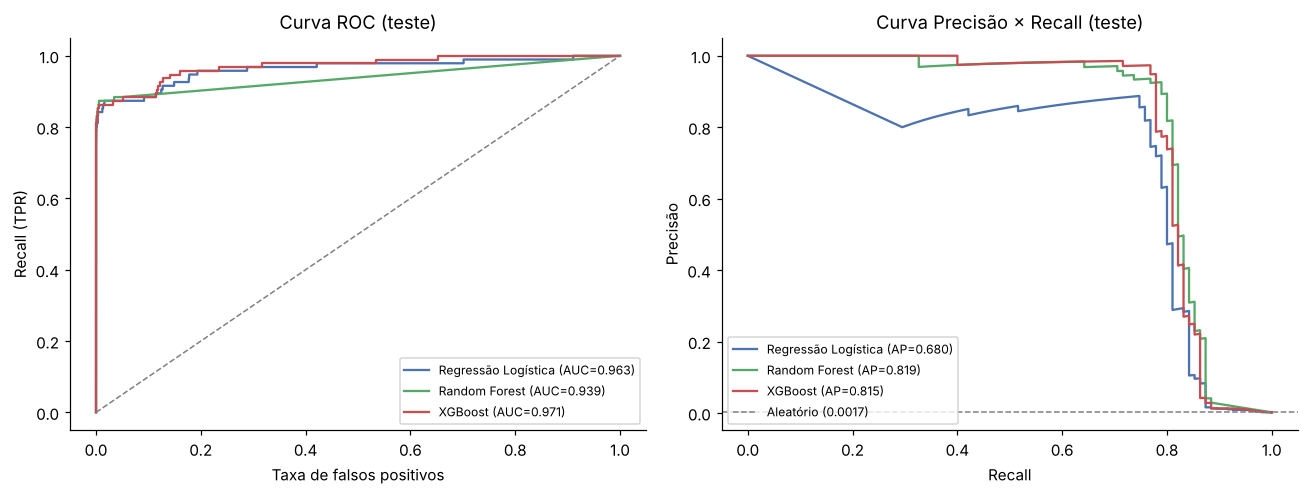

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for nome, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=CORES[nome], label=f"{nome} (AUC={roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=CORES[nome], label=f"{nome} (AP={average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", lw=1)
axes[0].set(title="Curva ROC (teste)", xlabel="Taxa de falsos positivos", ylabel="Recall (TPR)")
axes[1].axhline(y_test.mean(), ls="--", color="gray", lw=1, label=f"Aleatório ({y_test.mean():.4f})")
axes[1].set(title="Curva Precisão × Recall (teste)", xlabel="Recall", ylabel="Precisão")
for a in axes: a.legend(loc="lower right" if a is axes[0] else "lower left", fontsize=8)
plt.tight_layout(); plt.savefig("images/04_roc_pr.png", bbox_inches="tight"); plt.show()

**ROC × PR:** na ROC os três parecem ótimos (ROC-AUC entre 0,94 e 0,97), porque a taxa de falsos positivos é dividida por ~57 mil normais e fica sempre pequena. A curva **Precisão × Recall** é bem mais honesta em base desbalanceada e mostra a distância real entre a Regressão Logística e os modelos de árvore.

## 4. Ajustar o limiar de decisão

O `0,5` é arbitrário. Cada limiar é uma troca entre recall e precisão. Como **recall é a métrica principal**, mas um alerta falso também tem custo (cartão bloqueado, cliente irritado, analista revisando), o critério é:

> **Maximizar o F2 na validação.** O F2 pesa o recall **2× mais** que a precisão.

O limiar é escolhido **na validação** e aplicado **no teste**.

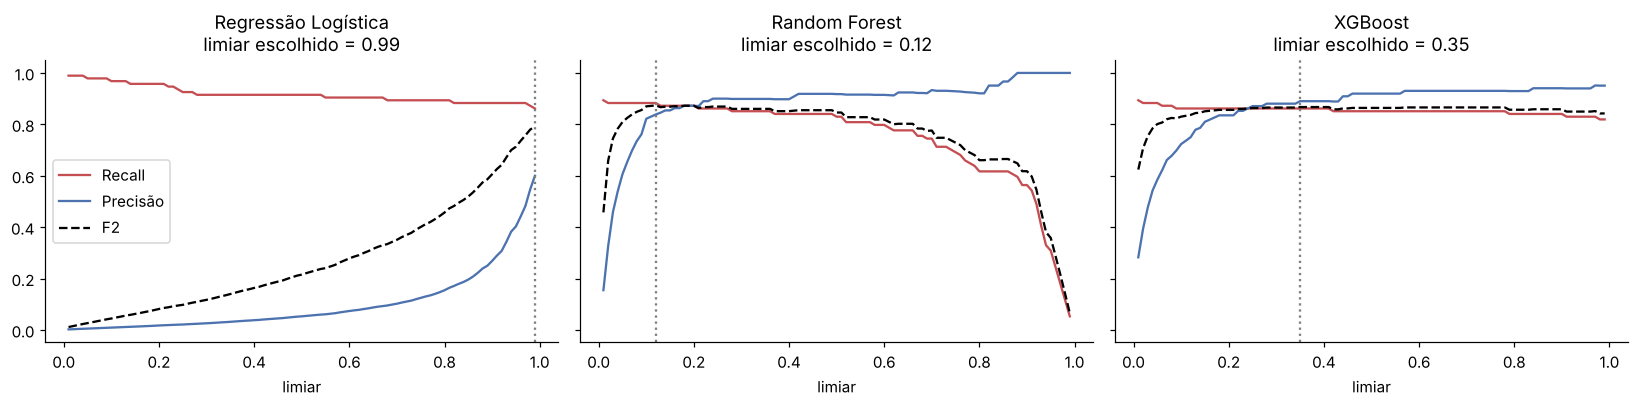

{'Regressão Logística': 0.99,
 'Random Forest': 0.12,
 'XGBoost': 0.35000000000000003}

In [13]:
def melhor_limiar(y_true, proba, beta=2):
    limiares = np.linspace(0.01, 0.99, 99)
    scores = [fbeta_score(y_true, (proba >= t).astype(int), beta=beta, zero_division=0) for t in limiares]
    return float(limiares[int(np.argmax(scores))]), limiares, scores

limiares_escolhidos = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (nome, p) in zip(axes, proba_val.items()):
    t_best, ts, f2s = melhor_limiar(y_val, p)
    limiares_escolhidos[nome] = t_best
    rec = [recall_score(y_val, (p >= t).astype(int)) for t in ts]
    pre = [precision_score(y_val, (p >= t).astype(int), zero_division=0) for t in ts]
    ax.plot(ts, rec, label="Recall", color="#C44E52")
    ax.plot(ts, pre, label="Precisão", color="#4C72B0")
    ax.plot(ts, f2s, label="F2", color="black", ls="--")
    ax.axvline(t_best, color="gray", ls=":")
    ax.set(title=f"{nome}\nlimiar escolhido = {t_best:.2f}", xlabel="limiar")
axes[0].legend(); plt.tight_layout(); plt.savefig("images/05_limiar.png", bbox_inches="tight"); plt.show()
limiares_escolhidos

In [14]:
linhas = []
for nome, p in proba_test.items():
    for rotulo, t in [("0,5 (padrão)", 0.5), ("ajustado (F2 na validação)", limiares_escolhidos[nome])]:
        linhas.append({"modelo": nome, "configuração": rotulo, **avaliar(y_test, p, t)})
comparacao = pd.DataFrame(linhas).set_index(["modelo", "configuração"])
comparacao[["limiar", "recall", "precisão", "F1", "PR-AUC", "fraudes pegas", "falsos alarmes"]]

limiar  recall  precisão  \
modelo              configuração                                           
Regressão Logística 0,5 (padrão)                0.5000  0.8737    0.0496   
                    ajustado (F2 na validação)  0.9900  0.8000    0.6281   
Random Forest       0,5 (padrão)                0.5000  0.7053    0.9571   
                    ajustado (F2 na validação)  0.1200  0.8000    0.8352   
XGBoost             0,5 (padrão)                0.5000  0.7789    0.9487   
                    ajustado (F2 na validação)  0.3500  0.7789    0.9024   

                                                   F1  PR-AUC fraudes pegas  \
modelo              configuração                                              
Regressão Logística 0,5 (padrão)               0.0938  0.6805         83/95   
                    ajustado (F2 na validação) 0.7037  0.6805         76/95   
Random Forest       0,5 (padrão)               0.8121  0.8189         67/95   
                    ajustado (F2 na validação) 0.8172  0.8189         76/95   
XGBoost             0,5 (padrão)               0.8555  0.8149         74/95   
                    ajustado (F2 na validação) 0.8362  0.8149         74/95   

                                                falsos alarmes  
modelo              configuração                                
Regressão Logística 0,5 (padrão)                          1591  
                    ajustado (F2 na validação)              45  
Random Forest       0,5 (padrão)                             3  
                    ajustado (F2 na validação)              15  
XGBoost             0,5 (padrão)                             4  
                    ajustado (F2 na validação)               8

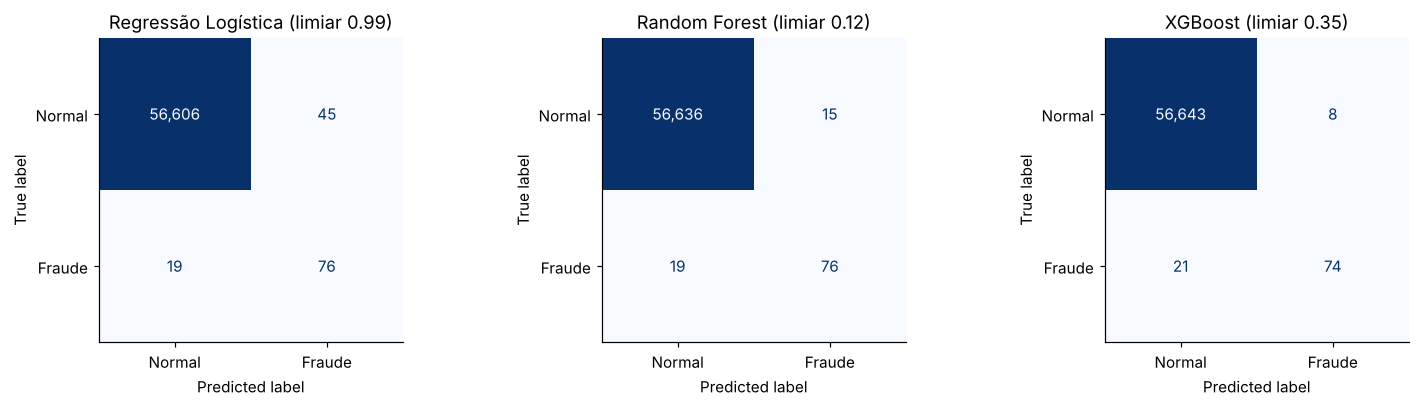

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (nome, p) in zip(axes, proba_test.items()):
    t = limiares_escolhidos[nome]
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= t).astype(int)),
                           display_labels=["Normal", "Fraude"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(f"{nome} (limiar {t:.2f})")
plt.tight_layout(); plt.savefig("images/06_matrizes_confusao.png", bbox_inches="tight"); plt.show()

## 5. Evoluções além da aula

### 5.1 Undersampling × Oversampling × SMOTE × peso de classe
A regra da Expert é **testar**. A reamostragem acontece **dentro do pipeline**, só no treino; validação e teste ficam com a proporção real.
Avaliação na **validação**, para não gastar o teste.

In [16]:
amostradores = {
    "peso de classe (sem reamostrar)": None,
    "undersampling (1:1)": RandomUnderSampler(random_state=SEED),
    "oversampling aleatório (1:1)": RandomOverSampler(random_state=SEED),
    "SMOTE (1:1)": SMOTE(random_state=SEED),
}

def montar(base, amostrador, usa_peso):
    if base == "Regressão Logística":
        clf = LogisticRegression(class_weight="balanced" if usa_peso else None, max_iter=2000, random_state=SEED)
        passos = [("scaler", StandardScaler())]
    else:
        clf = XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.9, colsample_bytree=0.8,
                            scale_pos_weight=peso_pos if usa_peso else 1, tree_method="hist",
                            n_jobs=-1, random_state=SEED)
        passos = []
    if amostrador is not None:
        passos.append(("sampler", amostrador))
    return ImbPipeline(passos + [("clf", clf)])

linhas = []
for base in ["Regressão Logística", "XGBoost"]:
    for nome_s, s in amostradores.items():
        t0 = time.time()
        m = montar(base, s, usa_peso=(s is None)).fit(X_train, y_train)
        p = m.predict_proba(X_val)[:, 1]
        linhas.append({"modelo": base, "estratégia": nome_s, **avaliar(y_val, p, 0.5),
                       "tempo (s)": round(time.time() - t0, 1)})
reamostragem = pd.DataFrame(linhas).set_index(["modelo", "estratégia"])
reamostragem[["recall", "precisão", "F1", "PR-AUC", "fraudes pegas", "falsos alarmes", "tempo (s)"]]

recall  precisão     F1  \
modelo              estratégia                                                 
Regressão Logística peso de classe (sem reamostrar)  0.9149    0.0531 0.1004   
                    undersampling (1:1)              0.9043    0.0263 0.0511   
                    oversampling aleatório (1:1)     0.9149    0.0533 0.1007   
                    SMOTE (1:1)                      0.9149    0.0478 0.0908   
XGBoost             peso de classe (sem reamostrar)  0.8511    0.9195 0.8840   
                    undersampling (1:1)              0.9149    0.0373 0.0717   
                    oversampling aleatório (1:1)     0.8617    0.9101 0.8852   
                    SMOTE (1:1)                      0.8617    0.7105 0.7788   

                                                     PR-AUC fraudes pegas  \
modelo              estratégia                                              
Regressão Logística peso de classe (sem reamostrar)  0.7895         86/94   
                    undersampling (1:1)              0.4687         85/94   
                    oversampling aleatório (1:1)     0.7902         86/94   
                    SMOTE (1:1)                      0.7910         86/94   
XGBoost             peso de classe (sem reamostrar)  0.8775         80/94   
                    undersampling (1:1)              0.6466         86/94   
                    oversampling aleatório (1:1)     0.8841         81/94   
                    SMOTE (1:1)                      0.8606         81/94   

                                                     falsos alarmes  tempo (s)  
modelo              estratégia                                                  
Regressão Logística peso de classe (sem reamostrar)            1533     0.5000  
                    undersampling (1:1)                        3149     0.2000  
                    oversampling aleatório (1:1)               1528     2.0000  
                    SMOTE (1:1)                                1715     2.0000  
XGBoost             peso de classe (sem reamostrar)               7     5.3000  
                    undersampling (1:1)                        2218     0.5000  
                    oversampling aleatório (1:1)                  8    10.9000  
                    SMOTE (1:1)                                  33    11.0000

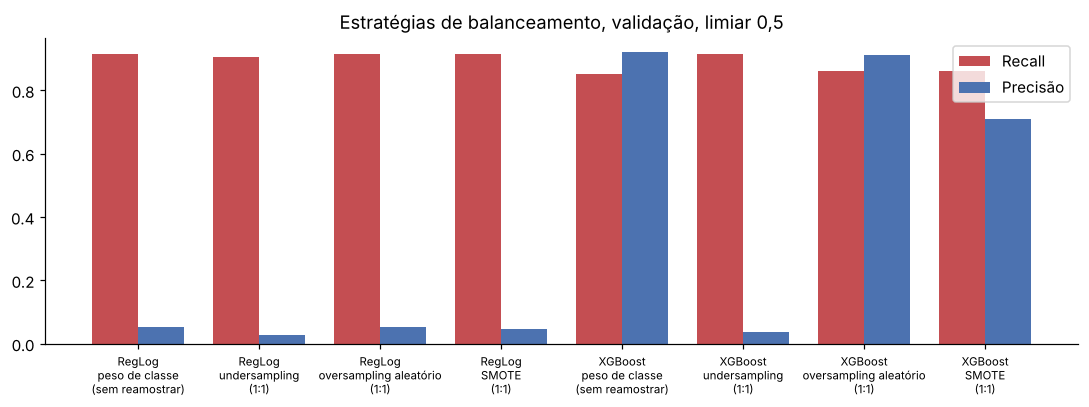

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.8))
r = reamostragem.reset_index()
r["rótulo"] = r["modelo"].str.replace("Regressão Logística", "RegLog") + "\n" + r["estratégia"].str.replace(" (", "\n(", regex=False)
x = np.arange(len(r)); w = 0.38
ax.bar(x - w/2, r["recall"], w, label="Recall", color="#C44E52")
ax.bar(x + w/2, r["precisão"], w, label="Precisão", color="#4C72B0")
ax.set_xticks(x); ax.set_xticklabels(r["rótulo"], fontsize=7.5); ax.legend()
ax.set_title("Estratégias de balanceamento, validação, limiar 0,5")
plt.tight_layout(); plt.savefig("images/07_reamostragem.png", bbox_inches="tight"); plt.show()

**Leitura:**
- **Undersampling** joga fora ~99,8% dos dados normais. No XGBoost o recall sobe (86/94), mas a precisão despenca para ~4% (mais de 2 mil falsos alarmes), e o PR-AUC cai de 0,88 para 0,65: o modelo nunca viu normais "parecidos com fraude".
- **Oversampling aleatório** empata com o peso de classe (PR-AUC 0,88, 1 fraude a mais, 1 falso alarme a mais), mas leva o dobro do tempo.
- **SMOTE** ficou pior que os dois no XGBoost (33 falsos alarmes): os pontos sintéticos criam fraudes "no meio" de regiões normais.
- Na Regressão Logística, nenhuma estratégia salva a precisão no limiar 0,5. O problema dela é a fronteira linear, não o balanceamento.

**Conclusão:** peso de classe é a opção mais simples e rápida com o mesmo resultado. Reamostrar basicamente desloca as probabilidades, e o ajuste de limiar faz esse trabalho de forma mais barata e controlável.

### 5.2 GridSearchCV ampliado (XGBoost)
Busca com validação cruzada estratificada (3 folds) otimizando **average precision (PR-AUC)**, não acurácia.

In [18]:
grid = GridSearchCV(
    XGBClassifier(scale_pos_weight=peso_pos, subsample=0.9, colsample_bytree=0.8, tree_method="hist",
                  eval_metric="aucpr", n_jobs=-1, random_state=SEED),
    param_grid={
        "n_estimators": [300, 600],
        "max_depth": [4, 6],
        "learning_rate": [0.03, 0.1],
        "min_child_weight": [1, 5],
    },
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    n_jobs=1, refit=True, verbose=0,
)
t0 = time.time(); grid.fit(X_train, y_train)
print(f"{len(grid.cv_results_['params'])} combinações × 3 folds em {time.time() - t0:.0f}s")
print("Melhores parâmetros:", grid.best_params_, f"| PR-AUC CV = {grid.best_score_:.4f}")

res = pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
res.sort_values("rank_test_score").head(6)

16 combinações × 3 folds em 177s
Melhores parâmetros: {'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 600} | PR-AUC CV = 0.8420


,params,mean_test_score,std_test_score,rank_test_score
5,"{'learning_rate': 0.03, 'max_depth': 6, 'min_c...",0.8420,0.0609,1
12,"{'learning_rate': 0.1, 'max_depth': 6, 'min_ch...",0.8415,0.0596,2
13,"{'learning_rate': 0.1, 'max_depth': 6, 'min_ch...",0.8415,0.0610,3
8,"{'learning_rate': 0.1, 'max_depth': 4, 'min_ch...",0.8409,0.0632,4
15,"{'learning_rate': 0.1, 'max_depth': 6, 'min_ch...",0.8397,0.0644,5
9,"{'learning_rate': 0.1, 'max_depth': 4, 'min_ch...",0.8390,0.0634,6


In [19]:
xgb_tunado = grid.best_estimator_
p_val_tun = xgb_tunado.predict_proba(X_val)[:, 1]
t_tun, _, _ = melhor_limiar(y_val, p_val_tun)
p_test_tun = xgb_tunado.predict_proba(X_test)[:, 1]
pd.DataFrame({
    "XGBoost (original)": avaliar(y_test, proba_test["XGBoost"], limiares_escolhidos["XGBoost"]),
    "XGBoost (GridSearch)": avaliar(y_test, p_test_tun, t_tun),
}).T[["limiar", "recall", "precisão", "F1", "PR-AUC", "fraudes pegas", "falsos alarmes"]]

,limiar,recall,precisão,F1,PR-AUC,fraudes pegas,falsos alarmes
XGBoost (original),0.3500,0.7789,0.9024,0.8362,0.8149,74/95,8
XGBoost (GridSearch),0.3600,0.7684,0.9012,0.8295,0.8212,73/95,8


### 5.3 Random Forest num pipeline com ajuste de limiar
O scikit-learn (≥ 1.5) tem o `TunedThresholdClassifierCV`, que **aprende o limiar por validação cruzada dentro do próprio estimador**. Assim o modelo já sai do `fit` com o limiar embutido e o `predict()` o usa direto, pronto para produção.

**Leitura:** o GridSearch achou um XGBoost um pouco melhor no ranking (PR-AUC sobe no CV e no teste), mas no limiar escolhido o resultado é praticamente o mesmo (1 fraude de diferença em 95). Os hiperparâmetros originais já estavam numa região boa, e o ganho de busca é pequeno perto do ganho do ajuste de limiar.

In [20]:
f2 = make_scorer(fbeta_score, beta=2)
rf_pipeline = TunedThresholdClassifierCV(
    RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight="balanced_subsample",
                           n_jobs=-1, random_state=SEED),
    scoring=f2, cv=3, random_state=SEED,
)
t0 = time.time(); rf_pipeline.fit(X_tmp, y_tmp)   # treino + validação; o CV interno faz o papel da validação
print(f"Treinado em {time.time() - t0:.0f}s | limiar aprendido = {rf_pipeline.best_threshold_:.3f}")

pred_rf = rf_pipeline.predict(X_test)  # já aplica o limiar aprendido
print(classification_report(y_test, pred_rf, target_names=["Normal", "Fraude"], digits=3))

Treinado em 212s | limiar aprendido = 0.111


              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     56651
      Fraude      0.835     0.800     0.817        95

    accuracy                          0.999     56746
   macro avg      0.917     0.900     0.908     56746
weighted avg      0.999     0.999     0.999     56746



### 5.4 Variáveis de comportamento ao longo do tempo
A base **não tem ID de cartão**, então não dá para montar o histórico de cada cliente. O que dá para medir é o **ritmo do sistema**: rajadas de transações em sequência.
Todas as janelas olham **só para o passado** (sem vazamento):
- `delta_t`: segundos desde a transação anterior
- `tx_ult_60s`: quantas transações aconteceram nos últimos 60 s
- `valor_vs_media_10min`: valor atual ÷ valor médio dos últimos 10 min

In [21]:
def variaveis_tempo(d):
    d = d.sort_values("Time").copy()
    ts = pd.to_datetime(d["Time"], unit="s")
    s = pd.Series(1, index=ts)
    d["delta_t"] = d["Time"].diff().fillna(0).values
    d["tx_ult_60s"] = s.rolling("60s", closed="left").count().fillna(0).values
    media_10m = pd.Series(d["Amount"].values, index=ts).rolling("600s", closed="left").mean()
    d["valor_vs_media_10min"] = (d["Amount"].values / (media_10m.fillna(d["Amount"].mean()).values + 1))
    return d.sort_index()

df_t = variaveis_tempo(df)
FEATURES_T = FEATURES + ["delta_t", "tx_ult_60s", "valor_vs_media_10min"]

def treina_xgb(cols):
    m = XGBClassifier(**{**grid.best_params_}, scale_pos_weight=peso_pos, subsample=0.9, colsample_bytree=0.8,
                      tree_method="hist", n_jobs=-1, random_state=SEED)
    m.fit(df_t.loc[X_train.index, cols], y_train)
    pv = m.predict_proba(df_t.loc[X_val.index, cols])[:, 1]
    t, _, _ = melhor_limiar(y_val, pv)
    return avaliar(y_val, pv, t)

pd.DataFrame({"sem variáveis de tempo": treina_xgb(FEATURES),
              "com variáveis de tempo": treina_xgb(FEATURES_T)}).T[
    ["limiar", "recall", "precisão", "F1", "PR-AUC", "fraudes pegas", "falsos alarmes"]]

,limiar,recall,precisão,F1,PR-AUC,fraudes pegas,falsos alarmes
sem variáveis de tempo,0.3600,0.8617,0.9000,0.8804,0.8829,81/94,9
com variáveis de tempo,0.2500,0.8617,0.9000,0.8804,0.8819,81/94,9


**Leitura:** o resultado é praticamente idêntico (mesmas 81/94 fraudes, mesmos 9 falsos alarmes, PR-AUC 0,883 × 0,882). Sem um identificador de cartão, o ritmo global de transações não carrega sinal novo. É um resultado negativo honesto: o valor real dessas variáveis aparece quando há histórico por cliente (velocidade de compras do mesmo cartão, distância do valor médio dele, etc.). Elas **não entram** no modelo final.

## 6. Explicar o modelo

Modelo final: **XGBoost com hiperparâmetros do GridSearch + limiar ajustado na validação**.

Por que ele: foi escolhido **antes de olhar o teste**, pelo melhor PR-AUC no CV (0,842) e pelo melhor equilíbrio na validação (86% de recall com 90% de precisão). No teste ele também tem o maior PR-AUC e o menor número de falsos alarmes. O Random Forest com limiar ajustado pegou 3 fraudes a mais no teste (76 × 73), mas com quase o dobro de falsos alarmes (15 × 8). Com só 95 fraudes no teste, 3 fraudes estão dentro da variação esperada. Se o negócio aceitar mais alertas, o RF com `TunedThresholdClassifierCV` é a alternativa direta (seção 7).

Limiar final: 0.36

              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     56651
      Fraude      0.901     0.768     0.830        95

    accuracy                          0.999     56746
   macro avg      0.950     0.884     0.915     56746
weighted avg      0.999     0.999     0.999     56746



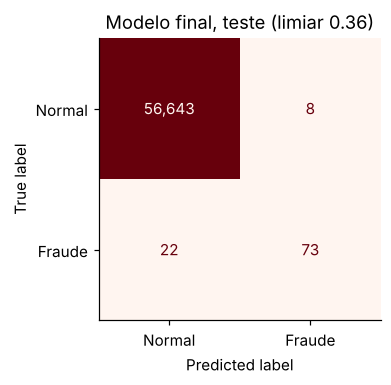

In [22]:
modelo_final, limiar_final = xgb_tunado, t_tun
p_final = p_test_tun
pred_final = (p_final >= limiar_final).astype(int)
print(f"Limiar final: {limiar_final:.2f}\n")
print(classification_report(y_test, pred_final, target_names=["Normal", "Fraude"], digits=3))

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final), display_labels=["Normal", "Fraude"]).plot(
    ax=ax, cmap="Reds", colorbar=False, values_format=",")
ax.set_title(f"Modelo final, teste (limiar {limiar_final:.2f})")
plt.tight_layout(); plt.savefig("images/08_matriz_final.png", bbox_inches="tight"); plt.show()

### 6.1 Importância das variáveis (visão global do modelo)

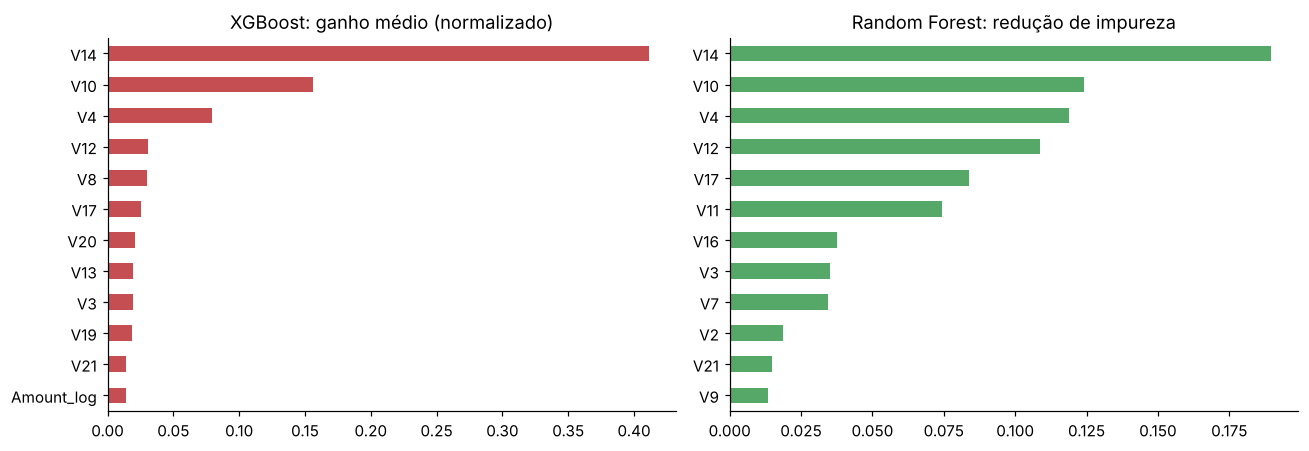

In [23]:
imp_xgb = pd.Series(modelo_final.get_booster().get_score(importance_type="gain")).reindex(FEATURES).fillna(0)
imp_rf = pd.Series(modelos["Random Forest"].feature_importances_, index=FEATURES)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
(imp_xgb / imp_xgb.sum()).sort_values().tail(12).plot.barh(ax=axes[0], color=CORES["XGBoost"])
axes[0].set_title("XGBoost: ganho médio (normalizado)")
(imp_rf / imp_rf.sum()).sort_values().tail(12).plot.barh(ax=axes[1], color=CORES["Random Forest"])
axes[1].set_title("Random Forest: redução de impureza")
plt.tight_layout(); plt.savefig("images/09_importancia.png", bbox_inches="tight"); plt.show()

### 6.2 SHAP: o que pesou em cada decisão
A importância global diz *quais* variáveis importam. O SHAP mostra **para que lado** cada valor empurra a previsão, transação por transação.
Para manter o cálculo rápido, usamos todas as fraudes do teste + uma amostra de 3.000 normais.

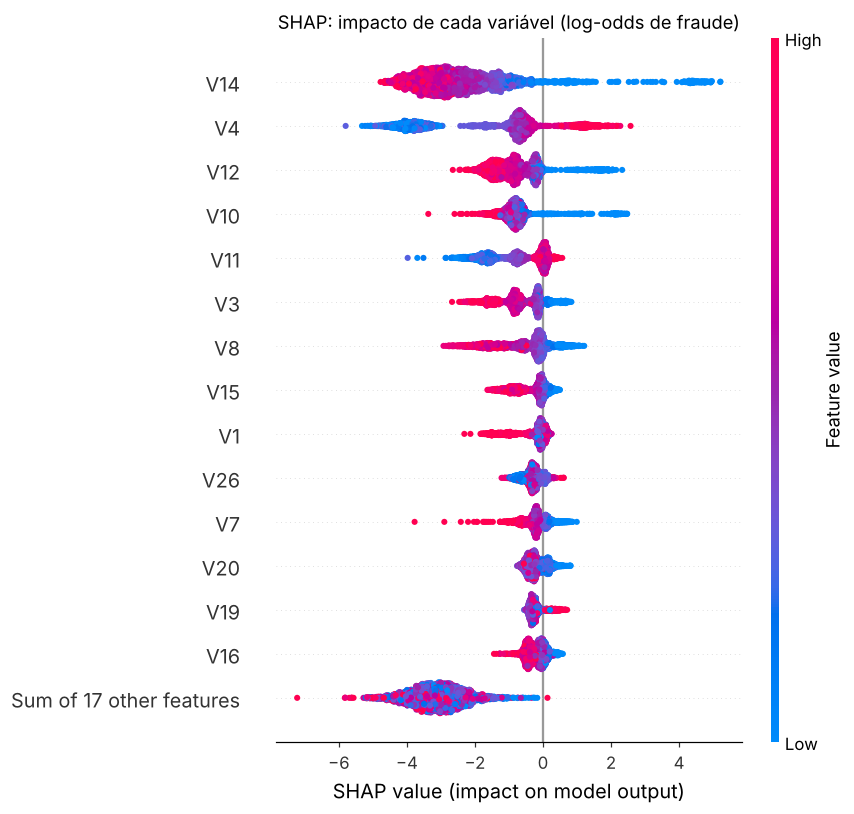

In [24]:
explainer = shap.TreeExplainer(modelo_final)
amostra = pd.concat([X_test[y_test == 1], X_test[y_test == 0].sample(3000, random_state=SEED)])
sv = explainer(amostra)

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP: impacto de cada variável (log-odds de fraude)")
plt.tight_layout(); plt.savefig("images/10_shap_beeswarm.png", bbox_inches="tight"); plt.show()

In [25]:
media_abs = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
media_abs.head(10).to_frame("|SHAP| médio")

,|SHAP| médio
V14,2.5667
V4,1.8023
V12,0.9353
V10,0.9066
V11,0.7981
V3,0.7131
V8,0.6521
V15,0.3778
V1,0.3307
V26,0.3183


#### Uma fraude detectada, explicada

Transação 229227: P(fraude) = 1.000


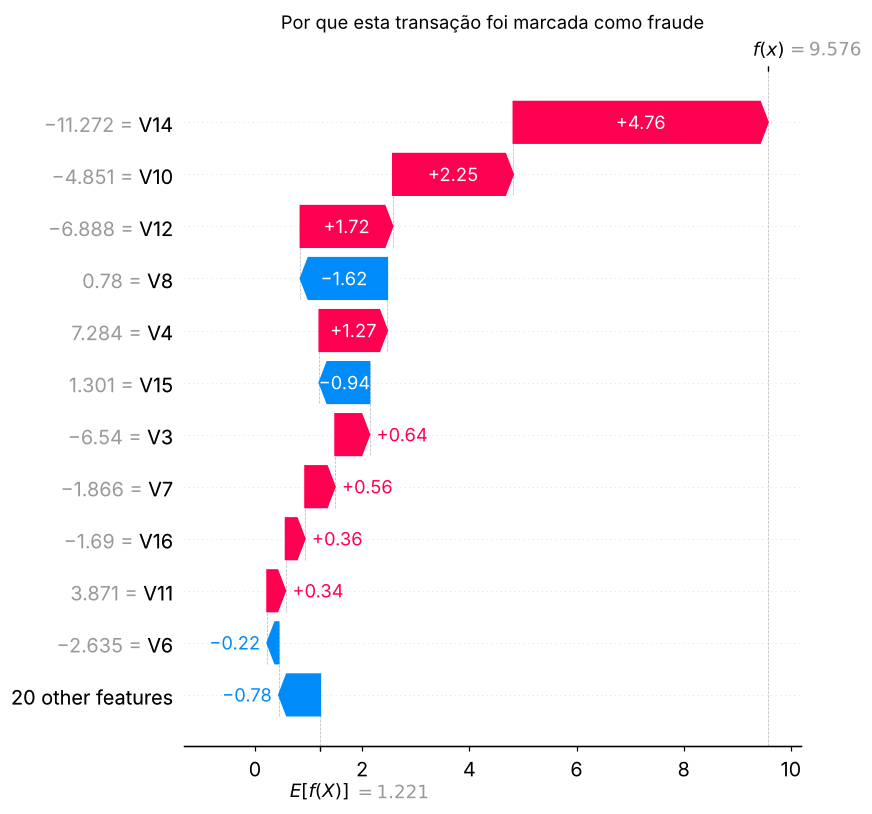

In [26]:
idx_fraudes = X_test.index[(y_test == 1) & (pred_final == 1)]
alvo = p_final[np.isin(X_test.index, idx_fraudes)]
i_tp = idx_fraudes[np.argsort(alvo)[len(alvo) // 2]]   # fraude "típica" (probabilidade mediana entre as detectadas)
pos = list(amostra.index).index(i_tp)
print(f"Transação {i_tp}: P(fraude) = {p_final[list(X_test.index).index(i_tp)]:.3f}")
shap.plots.waterfall(sv[pos], max_display=12, show=False)
plt.title("Por que esta transação foi marcada como fraude")
plt.tight_layout(); plt.savefig("images/11_shap_fraude_detectada.png", bbox_inches="tight"); plt.show()

#### Uma fraude que escapou, explicada

Transação 239334: P(fraude) = 0.009 (abaixo do limiar 0.36)


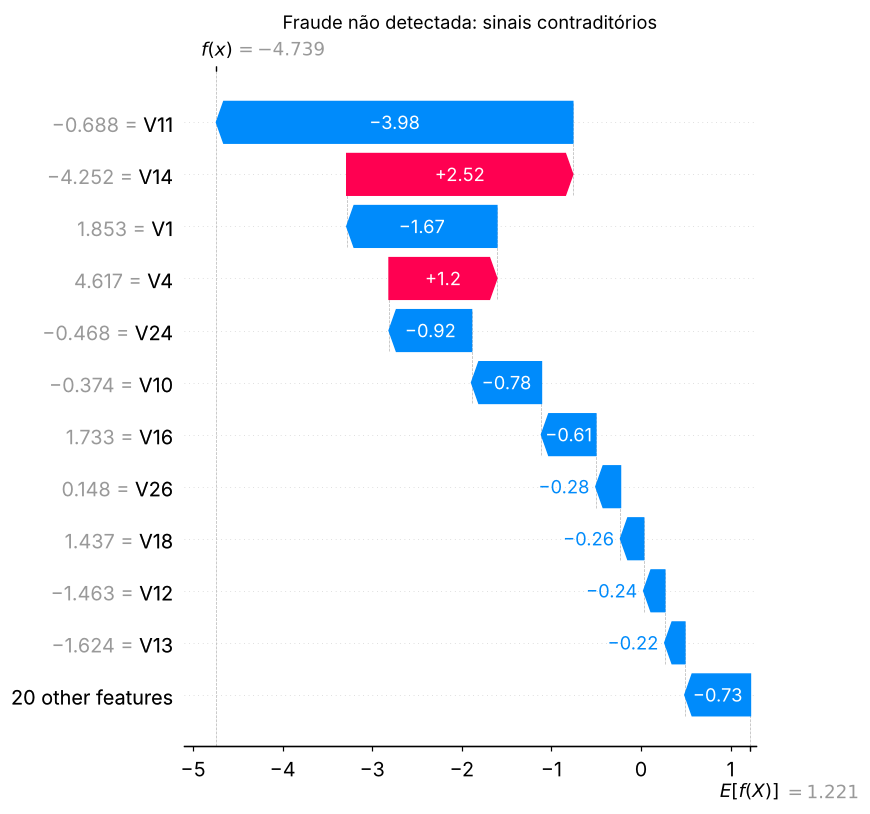

In [27]:
idx_fn = X_test.index[(y_test == 1) & (pred_final == 0)]
if len(idx_fn):
    i_fn = idx_fn[0]
    pos = list(amostra.index).index(i_fn)
    print(f"Transação {i_fn}: P(fraude) = {p_final[list(X_test.index).index(i_fn)]:.3f} (abaixo do limiar {limiar_final:.2f})")
    shap.plots.waterfall(sv[pos], max_display=12, show=False)
    plt.title("Fraude não detectada: sinais contraditórios")
    plt.tight_layout(); plt.savefig("images/12_shap_fraude_perdida.png", bbox_inches="tight"); plt.show()

**O que o SHAP mostrou:**
- **V14, V4, V12 e V10** dominam. Valores **muito negativos de V14, V12 e V10** e **valores altos de V4** empurram forte para fraude. É o mesmo padrão da correlação da EDA, agora quantificado por decisão.
- `Amount_log` e a hora têm peso pequeno: o sinal está quase todo nos componentes do PCA.
- **A fraude detectada** tem V14, V12 e V10 muito negativos e V4 alto, todos apontando na mesma direção, e chega a P(fraude) ≈ 1,0.
- **A fraude que escapou** tem sinais contraditórios: V14 e V4 empurram para fraude, mas V11, V1, V24 e V10 em faixas típicas de transação normal puxam com mais força, e ela termina com P(fraude) ≈ 0,01. Nenhum limiar razoável a pegaria. A próxima melhoria viria de **dados novos** (histórico por cartão), não de outro algoritmo ou outro limiar.

## 7. Conclusões

In [28]:
final = pd.DataFrame({
    "RegLog (0,5)": avaliar(y_test, proba_test["Regressão Logística"], 0.5),
    "RegLog (ajustado)": avaliar(y_test, proba_test["Regressão Logística"], limiares_escolhidos["Regressão Logística"]),
    "Random Forest (ajustado)": avaliar(y_test, proba_test["Random Forest"], limiares_escolhidos["Random Forest"]),
    "RF TunedThreshold": {**avaliar(y_test, rf_pipeline.predict_proba(X_test)[:, 1], rf_pipeline.best_threshold_)},
    "XGBoost (ajustado)": avaliar(y_test, proba_test["XGBoost"], limiares_escolhidos["XGBoost"]),
    "XGBoost GridSearch (FINAL)": avaliar(y_test, p_final, limiar_final),
}).T
final[["limiar", "recall", "precisão", "F1", "PR-AUC", "fraudes pegas", "falsos alarmes"]]

,limiar,recall,precisão,F1,PR-AUC,fraudes pegas,falsos alarmes
"RegLog (0,5)",0.5000,0.8737,0.0496,0.0938,0.6805,83/95,1591
RegLog (ajustado),0.9900,0.8000,0.6281,0.7037,0.6805,76/95,45
Random Forest (ajustado),0.1200,0.8000,0.8352,0.8172,0.8189,76/95,15
RF TunedThreshold,0.1111,0.8000,0.8352,0.8172,0.8094,76/95,15
XGBoost (ajustado),0.3500,0.7789,0.9024,0.8362,0.8149,74/95,8
XGBoost GridSearch (FINAL),0.3600,0.7684,0.9012,0.8295,0.8212,73/95,8


1. **Acurácia não serve**: o classificador "nunca é fraude" tem 99,8% e recall zero. Todos os modelos treinados passam de 97% de acurácia, inclusive os ruins.
2. **Peso de classe + ajuste de limiar** resolveram o desbalanceamento tão bem quanto (ou melhor que) under/oversampling, com treino mais rápido e sem descartar dados.
3. **O limiar é uma decisão de negócio**: escolhido por F2 na validação, ele troca alguns falsos alarmes por fraudes a mais pegas. Com outro custo de alerta, mudaria.
4. **XGBoost (GridSearch)** foi o modelo final: melhor PR-AUC e menos falsos alarmes (77% de recall, 90% de precisão no teste). O **Random Forest** com limiar ajustado é a alternativa se o recall pesar ainda mais (80% de recall, 84% de precisão). A **Regressão Logística**, mesmo com limiar ajustado, gera 45 falsos alarmes para pegar 76 fraudes, contra 15 do RF.
5. **SHAP** mostrou que V14, V4, V12 e V10 concentram a decisão e que as fraudes perdidas "se parecem" com transações normais nessas variáveis.

**Próximos passos:** dados com ID de cartão para variáveis de comportamento reais; calibrar as probabilidades; definir o limiar por custo financeiro (valor da fraude × custo de revisão) em vez de F2.